# 00 - Setup and configuration
**Project:** Spatiotemporal modelling and prediction of agricultural stress and land subsidence in the
Lake Naivasha Basin, Kenya (2015-2024) with Sentinel-1 InSAR, Sentinel-2 and Random Forest.

**What this notebook does** (run it first, once per project):
1. Detects where it is running (Colab / Jupyter / VS Code ...) and picks the project folder.
2. Configures `MODE`: `"real"` (Earth Engine + Sentinel-1) by default; `"demo"` is optional synthetic testing only.
3. Loads the Lake Naivasha catchment boundary, defines the analysis grid and model settings.
4. Creates the folder structure and saves everything to `config.json`, which every other notebook reads.

**Pipeline order:** 00 -> (00b demo only) -> 01 -> 02 -> 03 -> 04 -> 05 -> 06 -> 07 -> 08

In [1]:
# Cell 1 - Environment (identical in every notebook). Runs on Colab, Jupyter, VS Code, PyCharm, Spyder.
import os, sys, json, subprocess, importlib
from pathlib import Path

USE_DRIVE = True      # Colab only: keep project files on Google Drive so they survive a restart


def ensure(*pip_names):
    """Import each package; pip-install it first if it is missing."""
    import_names = {"scikit-learn": "sklearn", "earthengine-api": "ee", "hyp3-sdk": "hyp3_sdk",
                    "asf-search": "asf_search", "pillow": "PIL"}
    for pkg in pip_names:
        try:
            module_name = import_names[pkg] if pkg in import_names else pkg
            importlib.import_module(module_name)
        except ImportError:
            print("Installing", pkg, "...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])


IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    colab = importlib.import_module("google.colab")
    colab.drive.mount("/content/drive")
    default_dir = "/content/drive/MyDrive/naivasha_project"
elif IN_COLAB:
    default_dir = "/content/naivasha_project"
else:
    cwd = Path.cwd()
    default_dir = cwd.parent if cwd.name in ("notebooks", "scripts") else cwd
PROJECT_DIR = Path(os.environ.get("NAIVASHA_DIR", default_dir))   # override with env var NAIVASHA_DIR
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print("Running on:", "Google Colab" if IN_COLAB else "local Python", "| project folder:", PROJECT_DIR)

Running on: local Python | project folder: c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3


## 1. Your settings
Edit only this cell. Everything else in the project follows from it.

In [2]:
# Cell 2 - User settings
MODE = "real"                      # Use live Earth Engine and Sentinel-1 data; set to "demo" only for synthetic testing
GEE_PROJECT = "operating-rush-505912-s8"   # Google Cloud project registered for Earth Engine

# Real mode uses the complete Lake Naivasha drainage basin from HydroBASINS in Earth Engine.
# The seed must be on land inside the basin; the Naivasha town coordinates below are used.
# Demo mode retains this small rectangle so the synthetic example remains quick.
DEMO_BBOX = [36.20, -1.05, 36.60, -0.55]
HYDROBASINS_ASSET = "WWF/HydroSHEDS/v1/Basins/hybas_8"
CRS = "EPSG:32737"                 # UTM zone 37S: metres, covers Naivasha
START_YEAR, END_YEAR = 2015, 2024  # study period
RES = 100 if MODE == "real" else 500   # grid cell size in metres (demo uses a coarse grid to run in seconds)

# Modelling choices (explained in docs/01_methodology.md)
BASELINE_YEARS = (2016, 2024)      # years used for the monthly climatology of each index (2015 is sparse)
HOLDOUT_START_YEAR = 2023          # stress forecast: train on targets before this year, test from this year on
FORECAST_HORIZON = 3               # months ahead to predict stress
STRESS_CLASS_BREAKS = (0.5, 1.0)   # stress score: <0.5 low, 0.5-1.0 moderate, >=1.0 high
SUBSIDENCE_CLASS_BREAKS = (-5.0, -15.0)   # mm/yr: > -5 stable, -5..-15 moderate, < -15 severe
SAMPLE_PIXELS = 5000 if MODE == "real" else 1500   # pixels sampled for the pixel-by-month panel
BLOCK_KM = 3.0 if MODE == "real" else 5.0          # spatial CV block size (km)
RF_TREES = 300 if MODE == "real" else 60
RANDOM_SEED = 42

# Points of interest (lon, lat). APPROXIMATE - replace with surveyed coordinates when you have them.
POINTS = {
    "olkaria_geothermal": (36.300, -0.910),
    "mt_longonot": (36.450, -0.917),
    "naivasha_town": (36.431, -0.717),
}

## 2. Packages
Installs anything that is missing (on Colab most are already there).

In [3]:
# Cell 3 - Core packages
ensure("numpy", "pandas", "scipy", "scikit-learn", "rasterio", "matplotlib", "pyarrow",
       "shap", "joblib", "pillow", "h5py", "folium", "requests", "pyproj", "geopandas")
import numpy as np, pandas as pd
print("numpy", np.__version__, "| pandas", pd.__version__)

c:\Users\user\Downloads\naivasha-pipeline-v3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy 2.5.4 | pandas 3.1.1


## 3. Folders

In [4]:
# Cell 4 - Create the folder structure
data_dir = "data" if MODE == "real" else "data_demo"
out_dir = "outputs" if MODE == "real" else "outputs_demo"
for sub in ["s2", "climate", "static", "insar", "derived", "ancillary"]:
    (PROJECT_DIR / data_dir / sub).mkdir(parents=True, exist_ok=True)
for sub in ["figures", "maps", "tables", "models"]:
    (PROJECT_DIR / out_dir / sub).mkdir(parents=True, exist_ok=True)
print("Data folder   :", PROJECT_DIR / data_dir)
print("Output folder :", PROJECT_DIR / out_dir)

Data folder   : c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\data
Output folder : c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\outputs


## 4. Study-area boundary
Real mode dissolves HydroBASINS level-8 sub-basins sharing the lake catchment's main outlet.
The source geometry is saved as a shapefile and in config.json so every notebook uses the same polygon.

In [5]:
# Cell 5 - Load the catchment boundary from Earth Engine
import geopandas as gpd
from shapely.geometry import MultiPolygon, box, mapping, shape
from shapely.ops import unary_union

if MODE == "real":
    ensure("earthengine-api")
    import ee
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)

    seed = ee.Geometry.Point(POINTS["naivasha_town"])
    hydrobasins = ee.FeatureCollection(HYDROBASINS_ASSET)
    seed_candidates = hydrobasins.filterBounds(seed)
    if seed_candidates.size().getInfo() == 0:
        raise ValueError(f"No HydroBASINS feature found at the Naivasha seed point: {POINTS['naivasha_town']}")
    seed_feature = seed_candidates.first()
    seed_properties = ee.Feature(seed_feature).toDictionary(
        ["HYBAS_ID", "MAIN_BAS", "UP_AREA", "ENDO"]
    ).getInfo()
    if not seed_properties or seed_properties.get("MAIN_BAS") is None:
        raise ValueError(f"No HydroBASINS feature found at the Naivasha seed point: {POINTS['naivasha_town']}")
    main_basin_id = int(seed_properties["MAIN_BAS"])
    basin_features = hydrobasins.filter(ee.Filter.eq("MAIN_BAS", main_basin_id))
    aoi_geometry = basin_features.geometry(maxError=100).getInfo()
    if not aoi_geometry or aoi_geometry.get("type") not in ("Polygon", "MultiPolygon"):
        raise ValueError(f"HydroBASINS returned no polygon for main basin {main_basin_id}.")
    basin_area_km2 = basin_features.geometry(maxError=100).area(maxError=100).divide(1e6).getInfo()

    aoi_shape = shape(aoi_geometry)
    if aoi_shape.is_empty or not aoi_shape.is_valid:
        raise ValueError(f"HydroBASINS returned an empty or invalid catchment geometry: {aoi_shape.is_valid=}")
    aoi_name = "Lake Naivasha catchment"
    aoi_source = HYDROBASINS_ASSET
    aoi_shapefile = PROJECT_DIR / data_dir / "ancillary" / "naivasha_catchment.shp"
    for suffix in (".shp", ".shx", ".dbf", ".prj", ".cpg"):
        sidecar = aoi_shapefile.with_suffix(suffix)
        if sidecar.exists():
            sidecar.unlink()
    boundary = gpd.GeoDataFrame(
        [{"main_basin": main_basin_id, "area_km2": basin_area_km2}],
        geometry=[aoi_shape], crs="EPSG:4326",
    )
    boundary.to_file(aoi_shapefile, driver="ESRI Shapefile", index=False)
    print(f"Loaded {aoi_name}: main basin {main_basin_id}, {basin_area_km2:,.0f} km2")
    print("Saved shapefile:", aoi_shapefile)
else:
    aoi_geometry = {
        "type": "Polygon",
        "coordinates": [[
            [DEMO_BBOX[0], DEMO_BBOX[1]], [DEMO_BBOX[2], DEMO_BBOX[1]],
            [DEMO_BBOX[2], DEMO_BBOX[3]], [DEMO_BBOX[0], DEMO_BBOX[3]],
            [DEMO_BBOX[0], DEMO_BBOX[1]],
        ]],
    }
    aoi_shape = box(*DEMO_BBOX)
    aoi_name, aoi_source = "Synthetic demo area", "configured demo rectangle"
    aoi_shapefile = PROJECT_DIR / data_dir / "ancillary" / "naivasha_catchment.shp"
    main_basin_id, basin_area_km2 = None, None
    boundary = gpd.GeoDataFrame(
        [{"main_basin": None, "area_km2": None}],
        geometry=[aoi_shape], crs="EPSG:4326",
    )
    boundary.to_file(aoi_shapefile, driver="ESRI Shapefile", index=False)

boundary = gpd.read_file(aoi_shapefile)
if boundary.empty or boundary.crs is None or boundary.geometry.isna().any() or boundary.geometry.is_empty.any():
    raise ValueError(f"The AOI shapefile is empty or has no usable CRS/geometries: {aoi_shapefile}")
aoi_shape = unary_union(boundary.to_crs("EPSG:4326").geometry)
if aoi_shape.is_empty or not aoi_shape.is_valid:
    raise ValueError(f"The AOI shapefile contains an empty or invalid geometry: {aoi_shapefile}")
aoi_geometry = mapping(aoi_shape)
print("Loaded AOI shapefile:", aoi_shapefile)

# ## 5. Analysis grid
# Every raster in the project (Sentinel-2 indices, climate, terrain, InSAR, predictions) is put on **one common grid**
# so that pixels line up exactly. Its rectangular extent encloses the polygon; pixels outside the boundary are masked.

Loaded Lake Naivasha catchment: main basin 1080044500, 3,253 km2
Saved shapefile: c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\data\ancillary\naivasha_catchment.shp
Loaded AOI shapefile: c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\data\ancillary\naivasha_catchment.shp


In [6]:
# Cell 6 - Compute the grid from the projected polygon bounds
from rasterio.warp import transform_bounds
west, south, east, north = aoi_shape.bounds
xmin_raw, ymin_raw, xmax_raw, ymax_raw = transform_bounds(
    "EPSG:4326", CRS, west, south, east, north, densify_pts=21
)
xmin, xmax = np.floor(xmin_raw / RES) * RES, np.ceil(xmax_raw / RES) * RES
ymin, ymax = np.floor(ymin_raw / RES) * RES, np.ceil(ymax_raw / RES) * RES
grid = dict(crs=CRS, res=RES, xmin=float(xmin), ymin=float(ymin), xmax=float(xmax), ymax=float(ymax),
            width=int((xmax - xmin) / RES), height=int((ymax - ymin) / RES))
print(grid)
print(f"{grid['width'] * grid['height']:,} pixels, ~{grid['width'] * grid['height'] * RES**2 / 1e6:,.0f} km2")

{'crs': 'EPSG:32737', 'res': 100, 'xmin': 174800.0, 'ymin': 9898500.0, 'xmax': 244100.0, 'ymax': 9984400.0, 'width': 693, 'height': 859}
595,287 pixels, ~5,953 km2


## 6. Earth Engine check (real mode only)

In [7]:
# Cell 7 - Test the Earth Engine connection and exact catchment geometry
if MODE == "real":
    print("Earth Engine OK. Sentinel-2 scenes over the AOI in 2020:",
          ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(ee.Geometry(aoi_geometry))
          .filterDate("2020-01-01", "2021-01-01").size().getInfo())
else:
    print("Demo mode: Earth Engine not needed.")

Earth Engine OK. Sentinel-2 scenes over the AOI in 2020: 434


## 7. Save the configuration

In [8]:
# Cell 8 - Write config.json
from shapely.geometry import mapping
cfg = dict(
    mode=MODE, gee_project=GEE_PROJECT,
    bbox=[west, south, east, north],
    aoi=dict(
        name=aoi_name, source=aoi_source, main_basin_id=main_basin_id,
        area_km2=basin_area_km2, geometry=mapping(aoi_shape),
        shapefile=str(aoi_shapefile.relative_to(PROJECT_DIR)) if aoi_shapefile else None,
    ),
    grid=grid,
    start_year=START_YEAR, end_year=END_YEAR, baseline_years=list(BASELINE_YEARS),
    holdout_start_year=HOLDOUT_START_YEAR, forecast_horizon=FORECAST_HORIZON,
    stress_class_breaks=list(STRESS_CLASS_BREAKS), subsidence_class_breaks=list(SUBSIDENCE_CLASS_BREAKS),
    sample_pixels=SAMPLE_PIXELS, block_km=BLOCK_KM, rf_trees=RF_TREES, seed=RANDOM_SEED,
    points={k: list(v) for k, v in POINTS.items()},
    paths=dict(data=data_dir, outputs=out_dir),
)
(PROJECT_DIR / "config.json").write_text(json.dumps(cfg, indent=2))
print("Saved", PROJECT_DIR / "config.json")

Saved c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\config.json


## 8. Preview the study area

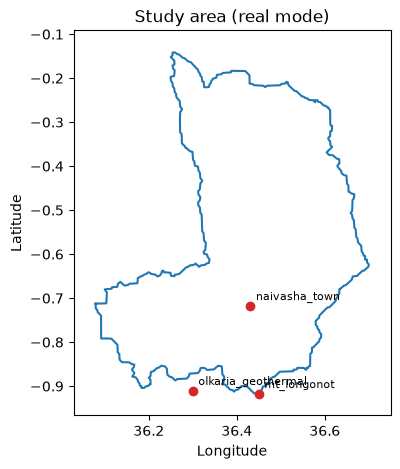

Saved interactive OSM basemap: c:\Users\user\Downloads\naivasha-pipeline-v3\naivasha-pipeline-v3\outputs\maps\00_study_area_interactive.html


In [9]:
# Cell 9 - Quick map of the catchment and points of interest
import matplotlib.pyplot as plt
import folium

fig, ax = plt.subplots(figsize=(5, 5))
geometries = list(aoi_shape.geoms) if isinstance(aoi_shape, MultiPolygon) else [aoi_shape]
for polygon in geometries:
    x, y = polygon.exterior.xy
    ax.plot(x, y, lw=1.5, color="tab:blue")
    for interior in polygon.interiors:
        x, y = interior.xy
        ax.plot(x, y, lw=0.8, color="tab:blue")
for name, (lon, lat) in POINTS.items():
    ax.plot(lon, lat, "o", color="tab:red"); ax.annotate(name, (lon, lat), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlim(west - 0.05, east + 0.05); ax.set_ylim(south - 0.05, north + 0.05)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title(f"Study area ({MODE} mode)"); ax.set_aspect("equal")
fig.savefig(PROJECT_DIR / out_dir / "figures" / "00_study_area.png", dpi=150, bbox_inches="tight")
plt.show()

study_map = folium.Map(
    location=[aoi_shape.centroid.y, aoi_shape.centroid.x],
    zoom_start=8,
    tiles="OpenStreetMap",
)
folium.GeoJson(
    aoi_geometry, name=aoi_name,
    style_function=lambda _: {"color": "#1769aa", "weight": 2, "fillOpacity": 0.06},
).add_to(study_map)
for name, (lon, lat) in POINTS.items():
    folium.Marker([lat, lon], tooltip=name).add_to(study_map)
folium.LayerControl().add_to(study_map)
study_map_path = PROJECT_DIR / out_dir / "maps" / "00_study_area_interactive.html"
study_map.save(study_map_path)
print("Saved interactive OSM basemap:", study_map_path)
study_map

**Next:** for this real-data run, continue with 01, 02, 03, and 04 in order.
`00b_demo_synthetic_data` is optional and must not be used for real analysis.